In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("/Users/subhadyutirath/Documents/Manufacturing/data/raw/ai4i2020.csv")

df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
df.shape

(10000, 14)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

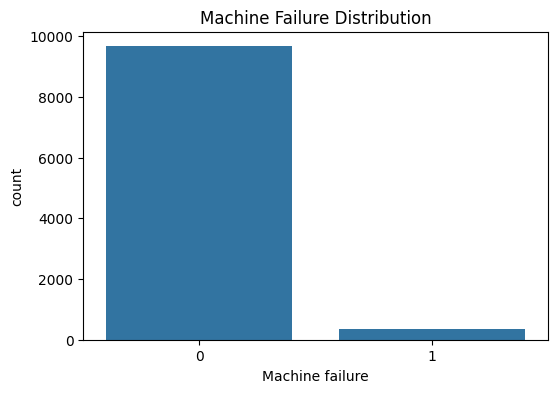

In [7]:
plt.figure(figsize=(6,4))

sns.countplot(x="Machine failure",data=df)

plt.title("Machine Failure Distribution")

plt.show()

In [8]:
def get_failure_type(row):

    if row["TWF"] == 1:
        return "Tool Wear Failure"

    elif row["HDF"] == 1:
        return "Heat Dissipation Failure"

    elif row["PWF"] == 1:
        return "Power Failure"

    elif row["OSF"] == 1:
        return "Overstrain Failure"

    elif row["RNF"] == 1:
        return "Random Failure"

    else:
        return "No Failure"


df["Failure_Type"] = df.apply(get_failure_type,axis=1)

In [9]:
df["Failure_Type"].value_counts()

Failure_Type
No Failure                  9652
Heat Dissipation Failure     115
Power Failure                 91
Overstrain Failure            78
Tool Wear Failure             46
Random Failure                18
Name: count, dtype: int64

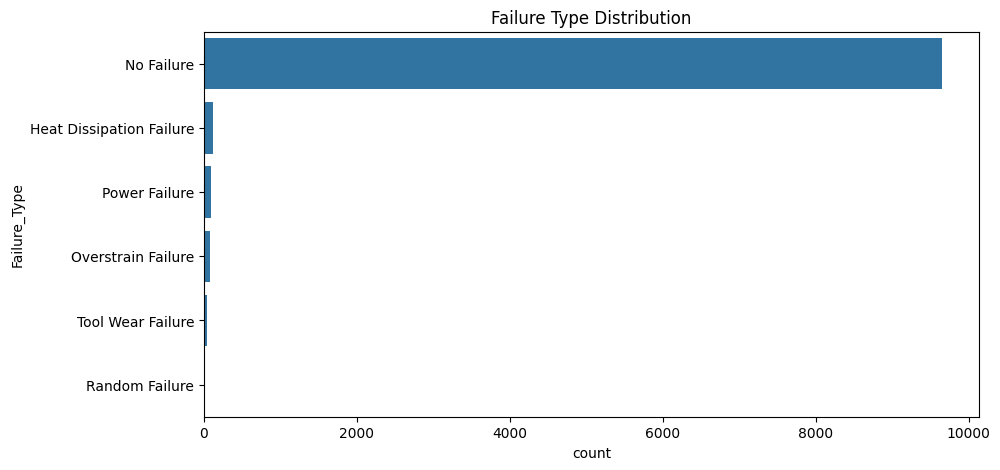

In [10]:
plt.figure(figsize=(10,5))

sns.countplot(y="Failure_Type",data=df,order=df["Failure_Type"].value_counts().index)

plt.title("Failure Type Distribution")

plt.show()

In [11]:
drop_cols = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

df = df.drop(columns=drop_cols)

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Type
0,M,298.1,308.6,1551,42.8,0,No Failure
1,L,298.2,308.7,1408,46.3,3,No Failure
2,L,298.1,308.5,1498,49.4,5,No Failure
3,L,298.2,308.6,1433,39.5,7,No Failure
4,L,298.2,308.7,1408,40.0,9,No Failure


In [12]:
df.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Failure_Type'],
      dtype='str')

In [13]:
from sklearn.preprocessing import LabelEncoder

type_encoder = LabelEncoder()

df["Type"] = type_encoder.fit_transform(df["Type"])

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Failure_Type
0,2,298.1,308.6,1551,42.8,0,No Failure
1,1,298.2,308.7,1408,46.3,3,No Failure
2,1,298.1,308.5,1498,49.4,5,No Failure
3,1,298.2,308.6,1433,39.5,7,No Failure
4,1,298.2,308.7,1408,40.0,9,No Failure


In [14]:
failure_encoder = LabelEncoder()

df["Failure_Type"] = (failure_encoder.fit_transform(df["Failure_Type"]))

In [15]:
mapping = dict(
    zip(
        failure_encoder.classes_,
        failure_encoder.transform(
            failure_encoder.classes_
        )
    )
)

mapping

{'Heat Dissipation Failure': np.int64(0),
 'No Failure': np.int64(1),
 'Overstrain Failure': np.int64(2),
 'Power Failure': np.int64(3),
 'Random Failure': np.int64(4),
 'Tool Wear Failure': np.int64(5)}

In [16]:
X = df.drop(columns=["Failure_Type"])

y = df["Failure_Type"]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)

In [18]:
print(X_train.shape)
print(X_test.shape)

(8000, 6)
(2000, 6)


In [19]:
pd.Series(y_train).value_counts()

Failure_Type
1    7722
0      92
3      73
2      62
5      37
4      14
Name: count, dtype: int64

In [20]:
pd.Series(y_test).value_counts()

Failure_Type
1    1930
0      23
3      18
2      16
5       9
4       4
Name: count, dtype: int64